# Prepaid Card Marketing — Mini-Project 2
## Part 3 of 5: Models and evaluation (Task B, Steps 7–8)

**Purpose.** Build three predictive models of prepaid card use (`PRODUSE_3`), compare them fairly, choose one, and hand its scores to the card-company (Task C) and CFPB (Task D) analyses.

| Section | What it delivers |
|---|---|
| 1. Setup | The shared split and 17 predictors, loaded through `prep.py` |
| 2. Three models | Logistic regression, random forest and XGBoost, each as a pipeline with the shared preparation step |
| 3. Tuning | A hyperparameter search per model, by cross-validation on the training set |
| 4. Comparison | All three models on the same five folds: ROC-AUC, PR-AUC, recall and precision at the top 20% |
| 5. Choice | The chosen model and why |
| 6. Threshold | The recall–precision trade-off and a recommended "top X%" rule |
| 7. Test-set evaluation | The one and only use of the test set: final numbers, confusion matrix, curves and lift |
| 8. Honest reading | What the model can and cannot do |
| 9. Hand-off | Saved scores and model for Tasks C and D |

### Summary

- **The three models are statistically tied.** Cross-validated PR-AUC is 0.225 (logistic regression), 0.228 (random forest) and 0.233 (XGBoost); ROC-AUC is 0.730, 0.723 and 0.723. Every gap is smaller than the fold-to-fold spread (0.028–0.049), and XGBoost beats logistic regression on PR-AUC in only 3 of the 5 folds.
- **Chosen model: logistic regression.** With no real difference in accuracy, the deciding factors are stability (it has the smallest fold-to-fold spread) and interpretability (one readable weight per predictor, which Tasks C and D need to explain who scores high and why).
- **Tuning added almost nothing,** for any model. The best settings beat Task A's untuned baseline (ROC-AUC 0.729, PR-AUC 0.224) by at most 0.009 in PR-AUC. This confirms Task A's finding: the signal is many weak, overlapping predictors, and a more flexible model cannot find much more.
- **Recommended rule: flag the top 20% of scores** (score of 0.602 or more). On the test set this flags 19.3% of people, catches **53.6% of all prepaid users**, and 24.4% of those flagged are users: **2.77 times** the 8.8% average.
- **Test-set results agree with cross-validation:** ROC-AUC 0.746 and PR-AUC 0.247 for the chosen model. The top 10% of scores contains 31.2% of all users; the top 30% contains 63.4%.
- **Performance is moderate, and that is the honest answer.** The model is good at sorting a population into a high-use group and a low-use group; it is not able to say with confidence whether a particular person uses a prepaid card. Three in four people it flags are not users.

---
# 1. Setup

Data comes through the shared module `prep.py`, exactly as Task A left it: the same 5,093 training and 1,274 test respondents, and the same 17 predictors. Nothing is re-split, re-cleaned or re-selected here.

**The test set is not touched until Section 7.** Every choice before that (settings, model, threshold) is made by cross-validation on the training set.

In [1]:
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
import sklearn
import xgboost
from xgboost import XGBClassifier

import prep
from prep import build_preprocessor, load_split

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 110, "display.max_rows", 100)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
SEED = 42

# Baseline to beat, from 02_features_and_prep.ipynb Section 5 (class-weighted logistic regression, default settings)
BASELINE_ROC_AUC, BASELINE_PR_AUC = 0.729, 0.224   # Task A, Section 5

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
})
MODEL_COLOURS = {"Logistic regression": BLUE, "Random forest": "#1f9e74", "XGBoost": ORANGE}


def fmt(df, formats, hide_index=False):
    """Return a display copy of a table with numbers formatted as text."""
    out = df.copy()
    if isinstance(formats, str):
        formats = {c: formats for c in out.columns if pd.api.types.is_numeric_dtype(out[c])}
    for col, pattern in formats.items():
        if col in out.columns:
            out[col] = out[col].map(lambda v, p=pattern: p.format(v) if pd.notna(v) else "")
    return out.reset_index(drop=True) if hide_index else out


X_train, X_test, y_train, y_test = load_split()
base_rate = y_train.mean()
print(f"scikit-learn {sklearn.__version__}, XGBoost {xgboost.__version__}")
print(f"Training set: {X_train.shape[0]:,} respondents x {X_train.shape[1]} predictors, {int(y_train.sum())} prepaid users ({base_rate:.1%})")
print(f"Test set:     {X_test.shape[0]:,} respondents, {int(y_test.sum())} prepaid users ({y_test.mean():.1%}) -- not used until Section 7")
print(f"Baseline to beat (cross-validated): ROC-AUC {BASELINE_ROC_AUC:.3f}, PR-AUC {BASELINE_PR_AUC:.3f}")

scikit-learn 1.9.1, XGBoost 3.4.1
Training set: 5,093 respondents x 17 predictors, 448 prepaid users (8.8%)
Test set:     1,274 respondents, 112 prepaid users (8.8%) -- not used until Section 7
Baseline to beat (cross-validated): ROC-AUC 0.729, PR-AUC 0.224


**Result.** 5,093 training respondents (448 prepaid users) and 1,274 test respondents (112 users), both 8.8%. The baseline to beat is Task A's untuned, class-weighted logistic regression: cross-validated **ROC-AUC 0.729** and **PR-AUC 0.224**.

---
# 2. Three models

The brief allows six model types. Three are used, chosen to span the range from simplest to most flexible:

| Model | How it works, in one line | Why it is here | How it handles the 1-to-10 imbalance |
|---|---|---|---|
| **Logistic regression** | Adds up a weight for each predictor and turns the total into a score | Simplest; each weight can be read and explained | `class_weight="balanced"`: each user counts as much as about 10 non-users |
| **Random forest** | Averages hundreds of decision trees, each grown on a random sample of people and predictors | Captures interactions (for example, age mattering only at low incomes) without being told | `class_weight="balanced_subsample"`: the same reweighting, inside each tree's sample |
| **XGBoost** | Builds small trees one after another, each correcting the mistakes of those before it | Usually the strongest model on tabular data | `scale_pos_weight` = ratio of non-users to users |

Every model is a **pipeline**: `build_preprocessor()` (fill gaps, one-hot encode, standardise) followed by the model. The preparation step is therefore re-learned from the training folds inside every cross-validation split, so nothing about the held-out fold leaks in.

**Settings searched.** Each model gets a modest grid of the settings that matter most for it:
- Logistic regression: `C`, the strength of the penalty that shrinks weights (small `C` = stronger shrinking, a simpler model).
- Random forest: tree depth, minimum people per leaf, and how many predictors each split may consider. Smaller trees and bigger leaves guard against fitting noise.
- XGBoost: tree depth, learning rate (how big a step each new tree takes) and minimum leaf weight. The number of trees is fixed at 300.

In [2]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_list = list(folds.split(X_train, y_train))     # the same five folds for every model, so comparisons are paired
neg_to_pos = (y_train == 0).sum() / (y_train == 1).sum()

MODELS = {
    "Logistic regression": dict(
        key="logit",
        estimator=LogisticRegression(class_weight="balanced", max_iter=5000, random_state=SEED),
        grid={"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    ),
    "Random forest": dict(
        key="rf",
        estimator=RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        grid={"model__max_depth": [4, 8, None], "model__min_samples_leaf": [10, 25, 50], "model__max_features": ["sqrt", 0.5]},
    ),
    "XGBoost": dict(
        key="xgb",
        estimator=XGBClassifier(n_estimators=300, scale_pos_weight=neg_to_pos, subsample=0.8, colsample_bytree=0.8,
                                eval_metric="logloss", n_jobs=-1, random_state=SEED),
        grid={"model__max_depth": [1, 2, 3, 4], "model__learning_rate": [0.01, 0.02, 0.05, 0.1], "model__min_child_weight": [1, 10]},
    ),
}
for spec in MODELS.values():
    spec["pipeline"] = Pipeline([("prep", build_preprocessor()), ("model", spec["estimator"])])

grid_table = pd.DataFrame([{"Model": name, "Setting": p.replace("model__", ""), "Values tried": ", ".join(map(str, v))}
                           for name, spec in MODELS.items() for p, v in spec["grid"].items()])
grid_table["Combinations for this model"] = grid_table["Model"].map({n: int(np.prod([len(v) for v in s["grid"].values()])) for n, s in MODELS.items()})
print(f"Class imbalance: {neg_to_pos:.1f} non-users for every user. XGBoost's scale_pos_weight is set to this ratio.")
display(grid_table)

Class imbalance: 10.4 non-users for every user. XGBoost's scale_pos_weight is set to this ratio.


,Model,Setting,Values tried,Combinations for this model
0,Logistic regression,C,"0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10",9
1,Random forest,max_depth,"4, 8, None",18
2,Random forest,min_samples_leaf,"10, 25, 50",18
3,Random forest,max_features,"sqrt, 0.5",18
4,XGBoost,max_depth,"1, 2, 3, 4",32
5,XGBoost,learning_rate,"0.01, 0.02, 0.05, 0.1",32
6,XGBoost,min_child_weight,"1, 10",32


---
# 3. Tuning

Every setting in the grid is scored by 5-fold cross-validation on the training set (`StratifiedKFold(5, shuffle=True, random_state=42)`): the model is fitted on four-fifths of the training respondents and scored on the remaining fifth, five times over. All three models use **the same five folds**.

Two measures are used throughout. Both judge how well a model **ranks** people, which is what a marketer or a regulator needs: who is most likely to use a prepaid card.

- **PR-AUC** (average precision): how precise the model is, averaged over every possible cut-off. A random ranking scores the base rate, **0.088**; a perfect one scores 1.0. It focuses on the users, the rare group that matters, so it is the measure the search optimises.
- **ROC-AUC**: the chance that a randomly picked user gets a higher score than a randomly picked non-user. 0.5 is a coin flip; 1.0 is perfect.

The **fold-to-fold standard deviation** (sd) shows how much a score moves just from which people land in which fold. Differences smaller than this are noise.

In [3]:
search_results, best_rows = {}, []
for name, spec in MODELS.items():
    search = GridSearchCV(spec["pipeline"], spec["grid"], cv=fold_list, refit="pr_auc", n_jobs=1,
                          scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
    search.fit(X_train, y_train)
    spec["search"], spec["best"] = search, search.best_estimator_
    res = pd.DataFrame(search.cv_results_)
    search_results[name] = res
    b = search.best_index_
    best_rows.append({"Model": name,
                      "Best settings": ", ".join(f"{k.replace('model__', '')}={v}" for k, v in search.best_params_.items()),
                      "PR-AUC": res.loc[b, "mean_test_pr_auc"], "PR-AUC sd": res.loc[b, "std_test_pr_auc"],
                      "ROC-AUC": res.loc[b, "mean_test_roc_auc"], "ROC-AUC sd": res.loc[b, "std_test_roc_auc"],
                      "Worst setting PR-AUC": res["mean_test_pr_auc"].min()})
best_table = pd.DataFrame(best_rows).set_index("Model")
print("Best setting per model (mean of 5 folds; sd = fold-to-fold standard deviation):")
display(fmt(best_table, "{:.3f}"))

Best setting per model (mean of 5 folds; sd = fold-to-fold standard deviation):


,Best settings,PR-AUC,PR-AUC sd,ROC-AUC,ROC-AUC sd,Worst setting PR-AUC
Model,,,,,,
Logistic regression,C=0.3,0.225,0.028,0.730,0.030,0.214
Random forest,"max_depth=None, max_features=sqrt, min_samples_leaf=10",0.228,0.049,0.723,0.044,0.219
XGBoost,"learning_rate=0.01, max_depth=2, min_child_weight=10",0.233,0.046,0.723,0.037,0.190


In [4]:
for name, res in search_results.items():
    params = [c for c in res.columns if c.startswith("param_")]
    top = res.sort_values("rank_test_pr_auc").head(5)[params + ["mean_test_pr_auc", "std_test_pr_auc", "mean_test_roc_auc"]]
    top.columns = [c.replace("param_model__", "") for c in params] + ["PR-AUC", "PR-AUC sd", "ROC-AUC"]
    print(f"{name}: five best of {len(res)} settings")
    display(fmt(top, {"PR-AUC": "{:.3f}", "PR-AUC sd": "{:.3f}", "ROC-AUC": "{:.3f}"}, hide_index=True))

Logistic regression: five best of 9 settings


,C,PR-AUC,PR-AUC sd,ROC-AUC
0,0.3,0.225,0.028,0.730
1,3.0,0.224,0.028,0.729
2,1.0,0.224,0.028,0.729
3,10.0,0.224,0.028,0.729
4,0.1,0.224,0.028,0.731


Random forest: five best of 18 settings


,max_depth,max_features,min_samples_leaf,PR-AUC,PR-AUC sd,ROC-AUC
0,None,sqrt,10,0.228,0.049,0.723
1,None,sqrt,25,0.227,0.046,0.725
2,None,sqrt,50,0.227,0.045,0.724
3,8,sqrt,50,0.226,0.046,0.724
4,8,sqrt,10,0.226,0.046,0.722


XGBoost: five best of 32 settings


,learning_rate,max_depth,min_child_weight,PR-AUC,PR-AUC sd,ROC-AUC
0,0.01,2,10,0.233,0.046,0.723
1,0.05,1,10,0.232,0.036,0.723
2,0.01,2,1,0.232,0.047,0.723
3,0.02,2,1,0.232,0.037,0.722
4,0.05,1,1,0.232,0.034,0.722


**Takeaways**

- **Logistic regression:** best `C` = 0.3, PR-AUC **0.225 ± 0.028**, ROC-AUC **0.730 ± 0.030**. Every `C` from 0.1 to 10 gives 0.224 or 0.225, so the penalty barely matters: the result is flat across the grid. Tuning leaves the model where Task A's baseline already was.
- **Random forest:** best is full-depth trees with at least 10 people per leaf and `sqrt` predictors per split. PR-AUC **0.228 ± 0.049**, ROC-AUC **0.723 ± 0.044**.
- **XGBoost:** best is very shallow trees (depth 2) with a slow learning rate (0.01). PR-AUC **0.233 ± 0.046**, ROC-AUC **0.723 ± 0.037**. Its five best settings all use trees of depth 1 or 2, which means XGBoost finds little in the way of interactions between predictors: a near-additive model, like a logistic regression, does nearly as well.
- **Settings matter less than the noise.** The spread from best to worst setting is 0.011 in PR-AUC for logistic regression and 0.009 for the random forest, well below the fold-to-fold sd. Only XGBoost has settings that clearly hurt (worst 0.190, from deep trees learning fast, which fit noise).

---
# 4. Comparison on cross-validation

The tuned version of each model is compared on the same five folds. Besides the two ranking measures, the table shows what happens at a **stated threshold**: flag the **top 20%** of scores in each fold.

- **Recall:** of all prepaid users, the share the model flags. "How many of the users do we reach?"
- **Precision:** of the people flagged, the share who are users. "How many of the people we reach are users?"

A share-based threshold ("top 20%") is used instead of a fixed score such as 0.5, because class-weighted models produce scores that are inflated and not comparable across models (Section 6 explains). Flagging the same share of people puts all three models on equal terms.

The scores below are **out-of-fold**: every training respondent is scored by the one model, of the five, that did not see them during fitting.

In [5]:
TOP_SHARE = 0.20      # the stated threshold for comparison: flag the 20% of people with the highest scores


def top_share_metrics(y, score, share=TOP_SHARE):
    """Recall and precision when the top `share` of scores are flagged."""
    y, score = np.asarray(y), np.asarray(score)
    cutoff = np.quantile(score, 1 - share)
    flagged = score >= cutoff
    hits = (flagged & (y == 1)).sum()
    return {"recall": hits / (y == 1).sum(), "precision": hits / flagged.sum()}


oof = {}
for name, spec in MODELS.items():
    # Out-of-fold scores: every training respondent is scored by a model that never saw them
    oof[name] = cross_val_predict(clone(spec["best"]), X_train, y_train, cv=fold_list, method="predict_proba")[:, 1]

per_fold = []
for name in MODELS:
    for f, (_, val) in enumerate(fold_list):
        y_val, s_val = y_train.iloc[val], oof[name][val]
        per_fold.append({"Model": name, "fold": f + 1, "ROC-AUC": roc_auc_score(y_val, s_val),
                         "PR-AUC": average_precision_score(y_val, s_val), **{
                         f"{k.capitalize()} at top 20%": v for k, v in top_share_metrics(y_val, s_val).items()}})
per_fold = pd.DataFrame(per_fold)
METRICS = ["ROC-AUC", "PR-AUC", "Recall at top 20%", "Precision at top 20%"]
grouped = per_fold.groupby("Model", sort=False)[METRICS]
means, sds = grouped.mean(), grouped.std(ddof=0)      # ddof=0 matches the sd reported by GridSearchCV in Section 3
cv_compare = pd.concat([means, sds.add_suffix(" sd")], axis=1)[[c for m in METRICS for c in (m, f"{m} sd")]]
cv_compare.loc["Baseline (Task A logistic regression)", ["ROC-AUC", "PR-AUC"]] = [BASELINE_ROC_AUC, BASELINE_PR_AUC]
print("Cross-validated comparison on the training set (mean and fold-to-fold sd over the same 5 folds):")
display(fmt(cv_compare, "{:.3f}"))

Cross-validated comparison on the training set (mean and fold-to-fold sd over the same 5 folds):


,ROC-AUC,ROC-AUC sd,PR-AUC,PR-AUC sd,Recall at top 20%,Recall at top 20% sd,Precision at top 20%,Precision at top 20% sd
Model,,,,,,,,
Logistic regression,0.730,0.030,0.225,0.028,0.484,0.051,0.213,0.022
Random forest,0.723,0.044,0.228,0.049,0.482,0.052,0.212,0.023
XGBoost,0.723,0.037,0.233,0.046,0.498,0.065,0.219,0.029
Baseline (Task A logistic regression),0.729,,0.224,,,,,


In [6]:
# Paired differences: same folds, so subtract fold by fold. A difference is only meaningful if it is large relative to its own spread.
wide = per_fold.pivot(index="fold", columns="Model")
pairs = [("XGBoost", "Logistic regression"), ("Random forest", "Logistic regression"), ("XGBoost", "Random forest")]
paired = []
for a, b in pairs:
    for m in ["ROC-AUC", "PR-AUC"]:
        d = wide[(m, a)] - wide[(m, b)]
        paired.append({"Comparison": f"{a} minus {b}", "Metric": m, "Mean difference": d.mean(), "sd of difference": d.std(ddof=0),
                       "Folds where first is better": f"{int((d > 0).sum())} of 5",
                       "Difference / sd": d.mean() / d.std(ddof=0)})
paired = pd.DataFrame(paired)
display(fmt(paired, {"Mean difference": "{:+.3f}", "sd of difference": "{:.3f}", "Difference / sd": "{:+.2f}"}, hide_index=True))

,Comparison,Metric,Mean difference,sd of difference,Folds where first is better,Difference / sd
0,XGBoost minus Logistic regression,ROC-AUC,-0.007,0.007,1 of 5,-0.93
1,XGBoost minus Logistic regression,PR-AUC,+0.009,0.024,3 of 5,+0.37
2,Random forest minus Logistic regression,ROC-AUC,-0.007,0.019,3 of 5,-0.37
3,Random forest minus Logistic regression,PR-AUC,+0.003,0.023,1 of 5,+0.13
4,XGBoost minus Random forest,ROC-AUC,+0.000,0.014,2 of 5,+0.02
5,XGBoost minus Random forest,PR-AUC,+0.006,0.012,3 of 5,+0.50


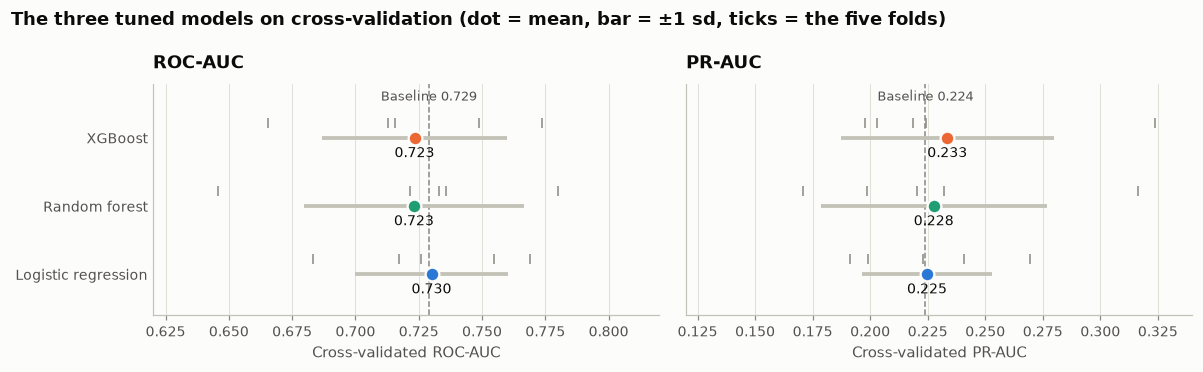

In [7]:
names = list(MODELS)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, metric, baseline, xlim in [(axes[0], "ROC-AUC", BASELINE_ROC_AUC, (0.62, 0.82)), (axes[1], "PR-AUC", BASELINE_PR_AUC, (0.12, 0.34))]:
    for i, name in enumerate(names):
        m, sd = cv_compare.loc[name, metric], cv_compare.loc[name, f"{metric} sd"]
        ax.errorbar(m, i, xerr=sd, fmt="o", color=MODEL_COLOURS[name], ecolor=AXIS, elinewidth=2.5, markersize=9,
                    markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
        ax.text(m, i - 0.28, f"{m:.3f}", ha="center", fontsize=9, color=INK)
        for f in range(5):
            ax.plot(wide.loc[f + 1, (metric, name)], i + 0.22, "|", color=MUTED, markersize=7)
    ax.axvline(baseline, color=MUTED, linestyle="--", linewidth=1)
    ax.text(baseline, len(names) - 0.45, f"Baseline {baseline:.3f}", fontsize=8.5, color=INK2, ha="center")
    ax.set_xlim(*xlim)
    ax.set_xlabel(f"Cross-validated {metric}")
    ax.set_title(metric)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(range(len(names)), names)
axes[0].set_ylim(-0.6, len(names) - 0.2)
fig.suptitle("The three tuned models on cross-validation (dot = mean, bar = ±1 sd, ticks = the five folds)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "15_cv_model_comparison.png")
plt.show()

**Takeaways**

- **The three models are tied.** XGBoost has the highest PR-AUC (0.233) and logistic regression the highest ROC-AUC (0.730). XGBoost's PR-AUC lead over logistic regression is +0.009, with a fold-by-fold spread of 0.024 (ratio +0.37), and it is ahead in only 3 of 5 folds; on ROC-AUC it is behind by 0.007. No pair of models differs by more than 0.93 times the spread of its difference.
- **The same holds at the top-20% threshold.** Recall is 48.4% (logistic regression), 48.2% (random forest) and 49.8% (XGBoost); precision is 21.3%, 21.2% and 21.9%. In practice, all three would flag nearly the same people.
- **Logistic regression is the most stable.** Its fold-to-fold sd is the smallest on every measure (0.030 ROC-AUC, 0.028 PR-AUC, against 0.037–0.049 for the tree models).
- **None clearly beats the baseline** (0.729 / 0.224). The ceiling is set by the information in the 17 predictors, not by the choice of algorithm.

---
# 5. Choosing one model

The model has to do three things for this project: rank people as well as the alternatives, give stable results, and be explainable to the card company and to the CFPB (Tasks C and D must say *why* someone scores high).

In [8]:
CHOSEN = "Logistic regression"
chosen_spec = MODELS[CHOSEN]
chosen_model = chosen_spec["best"]
coef = pd.Series(chosen_model.named_steps["model"].coef_[0], index=prep.readable_names(chosen_model.named_steps["prep"]))
print(f"Chosen model: {CHOSEN} ({best_table.loc[CHOSEN, 'Best settings']})")
print(f"Model columns: {len(coef)}, of which {int((coef.abs() > 1e-6).sum())} have a non-zero weight")
print("Largest weights (on the standardised scale; positive = higher score). Full interpretation is Task C:")
display(fmt(coef.reindex(coef.abs().sort_values(ascending=False).index).head(8).rename("weight").to_frame(), "{:+.2f}"))

Chosen model: Logistic regression (C=0.3)
Model columns: 26, of which 26 have a non-zero weight
Largest weights (on the standardised scale; positive = higher score). Full interpretation is Task C:


,weight
Has: Checking or Savings Account at a bank or credit union,-0.55
Primary or only employment status: Homemaker,-0.40
Contacted by debt collector in past 12 months,+0.38
Primary or only employment status: Full-time student,-0.32
"Primary or only employment status: Sick, disabled or unable to work",+0.30
Primary or only employment status: Retired,+0.27
Which one of the following best describes your housing situation?: Owns home,-0.26
I applied for credit and was turned down,+0.26


**Decision: logistic regression (`C` = 0.3, class-weighted).**

| Criterion | Logistic regression | Random forest | XGBoost |
|---|---|---|---|
| Ranking performance (cross-validated PR-AUC) | 0.225 | 0.228 | 0.233 |
| Better than logistic regression beyond the noise? | — | No (+0.003, ahead in 1 of 5 folds) | No (+0.009, ahead in 3 of 5 folds) |
| Stability (fold-to-fold sd of PR-AUC) | **0.028, smallest** | 0.049 | 0.046 |
| Interpretability | **One weight per predictor, with a direction** | 300 deep trees; needs permutation importance | 300 small trees; needs permutation importance |

**Why.**
1. **Performance is tied** (Section 4). When models are statistically indistinguishable, the brief's rule is to prefer the more interpretable one.
2. **It is the most stable.** Its scores move least from one fold to the next, so its rankings are least likely to depend on which people happened to be in the data.
3. **It can be explained to a non-specialist.** Every predictor has one weight: positive weights raise the score, negative ones lower it. Tasks C and D can turn these into odds ratios and say, for example, that having a bank account is associated with lower use, holding the other predictors fixed. The top weights above already match Part 1: no bank account, debt-collector contact, credit rejection and being sick or disabled raise the score, and owning a home lowers it.
4. **XGBoost's tuning points the same way:** it prefers trees of depth 1–2, which is close to an additive model, so little is lost by using one.

**What is given up:** about 0.009 in PR-AUC on cross-validation, which is within the noise. Section 7 reports all three on the test set so this can be checked.

---
# 6. Threshold: how many people to flag

The model gives everyone a score. Turning that into a decision ("send this person an offer", "treat this group as at risk") needs a cut-off, and the cut-off is a trade-off:

- **Flag more people** and you catch more of the users (higher recall), but a larger share of those flagged are not users (lower precision): more wasted marketing, or more people wrongly labelled at risk.
- **Flag fewer people** and those you flag are more likely to be users, but you miss most of the users.

**Why not the usual 0.5 cut-off?** The class weights make the model treat every user as if there were ten of them, which pushes all scores upward. The scores still **rank** people correctly, but they are not true probabilities: a score of 0.6 does not mean a 60% chance of using a prepaid card. So the threshold is stated as a **share of people** ("top X%"), which means the same thing whatever the scale.

The threshold is chosen here on the training set's out-of-fold scores, **before** the test set is opened.

In [9]:
chosen_oof = oof[CHOSEN]
shares = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
rows = []
for s in shares:
    m = top_share_metrics(y_train, chosen_oof, s)
    rows.append({"Share of people flagged": s, "Score cutoff": np.quantile(chosen_oof, 1 - s),
                 "People flagged (of 5,093)": int(round(s * len(y_train))),
                 "Recall (share of users caught)": m["recall"], "Precision (share of flagged who are users)": m["precision"],
                 "Lift over 8.8%": m["precision"] / base_rate})
tradeoff = pd.DataFrame(rows)
display(fmt(tradeoff, {"Share of people flagged": "{:.0%}", "Score cutoff": "{:.3f}", "People flagged (of 5,093)": "{:,}",
                       "Recall (share of users caught)": "{:.1%}", "Precision (share of flagged who are users)": "{:.1%}",
                       "Lift over 8.8%": "{:.2f}x"}, hide_index=True))

print(f"For reference, the default 0.5 cutoff on this class-weighted model flags {np.mean(chosen_oof >= 0.5):.0%} of people.")

,Share of people flagged,Score cutoff,"People flagged (of 5,093)",Recall (share of users caught),Precision (share of flagged who are users),Lift over 8.8%
0,5%,0.801,255,17.0%,29.8%,3.39x
1,10%,0.723,509,29.7%,26.1%,2.96x
2,15%,0.655,764,41.1%,24.1%,2.74x
3,20%,0.602,"1,019",48.7%,21.4%,2.43x
4,25%,0.552,"1,273",55.8%,19.6%,2.23x
5,30%,0.508,"1,528",61.4%,18.0%,2.05x
6,40%,0.434,"2,037",71.2%,15.7%,1.78x
7,50%,0.380,"2,546",79.2%,13.9%,1.58x


For reference, the default 0.5 cutoff on this class-weighted model flags 31% of people.


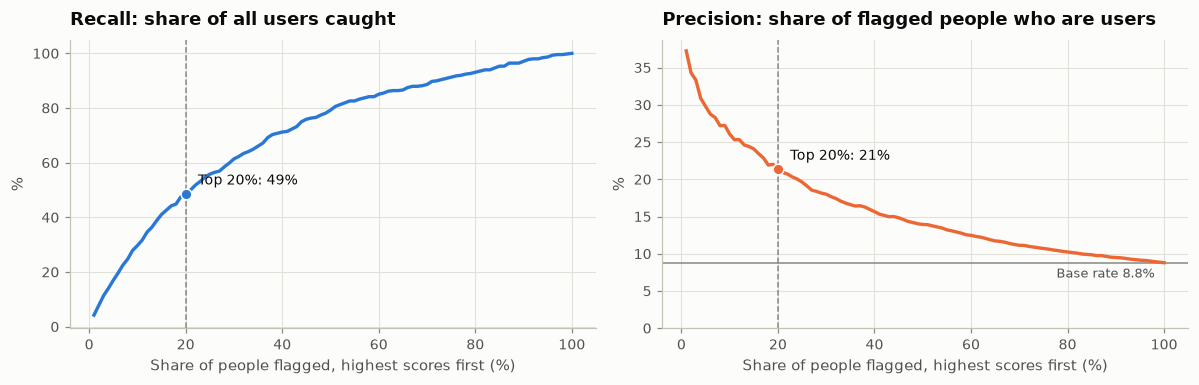

Recommended rule: flag the top 20% of scores. On the training scores that is a cutoff of 0.602.


In [10]:
grid_share = np.linspace(0.01, 1, 100)
curve = pd.DataFrame([top_share_metrics(y_train, chosen_oof, s) for s in grid_share], index=grid_share)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title, colour in [(axes[0], "recall", "Recall: share of all users caught", BLUE),
                               (axes[1], "precision", "Precision: share of flagged people who are users", ORANGE)]:
    ax.plot(curve.index * 100, curve[col] * 100, color=colour, linewidth=2.2, zorder=3)
    ax.axvline(TOP_SHARE * 100, color=MUTED, linestyle="--", linewidth=1)
    v = tradeoff.loc[tradeoff["Share of people flagged"] == TOP_SHARE].iloc[0]
    val = v["Recall (share of users caught)"] if col == "recall" else v["Precision (share of flagged who are users)"]
    ax.plot(TOP_SHARE * 100, val * 100, "o", color=colour, markersize=7, markeredgecolor=SURFACE, zorder=4)
    ax.annotate(f"Top 20%: {val:.0%}", (TOP_SHARE * 100, val * 100), xytext=(8, 6), textcoords="offset points", fontsize=9)
    ax.set_xlabel("Share of people flagged, highest scores first (%)")
    ax.set_ylabel("%")
    ax.set_title(title)
axes[1].axhline(base_rate * 100, color=MUTED, linewidth=1)
axes[1].set_ylim(0, None)
axes[1].text(98, base_rate * 100 - 2, "Base rate 8.8%", ha="right", fontsize=8.5, color=INK2)
fig.tight_layout()
fig.savefig(FIG_DIR / "16_threshold_tradeoff.png")
plt.show()

THRESHOLD = float(np.quantile(chosen_oof, 1 - TOP_SHARE))     # fixed on training data, applied unchanged to the test set
print(f"Recommended rule: flag the top {TOP_SHARE:.0%} of scores. On the training scores that is a cutoff of {THRESHOLD:.3f}.")

**Takeaways** (out-of-fold scores, all 5,093 training respondents pooled)

- **The trade-off is steep at the top.** Flagging the top 5% gives the highest precision (29.8%, 3.39 times the average) but catches only 17.0% of users. Flagging the top 50% catches 79.2% of users, but only 13.9% of those flagged are users, barely 1.6 times the average.
- **The default 0.5 cut-off would flag 31% of people,** a side effect of the class weights, not a deliberate choice. This is why the rule is stated as a share.
- **Recommendation: flag the top 20% of scores** (score of 0.602 or more). On the training scores this catches **48.7% of users at 21.4% precision, a lift of 2.43x**. It is the point where the model still finds about half the users, while those flagged remain well over twice as likely to be users as the average person. Beyond 20%, each extra person flagged adds users at close to the average rate.
- **Different uses can justify different shares.**
  - *Card company (Task C):* the top 10–20%, where marketing spend works hardest (lift 3.0x at 10%, 2.4x at 20%).
  - *CFPB (Task D):* missing an at-risk user is worse than flagging a non-user, so a wider net is defensible: the top 30% catches 61.4% of users.

(The 48.7% here pools all respondents; the 48.4% in Section 4 is the average of five per-fold figures. They measure the same thing in slightly different ways.)

---
# 7. Final test-set evaluation

**This is the first and only time the test set is used.** All three tuned models, each refitted on the full training set, score the 1,274 test respondents. The top-20% cut-off for each model was fixed on its training scores in the previous sections and is applied unchanged.

Test results for the two models not chosen are shown for transparency. They do not change the choice made in Section 5: re-choosing a model after looking at the test set would turn the test set into another tuning set.

**Lift** is the usage rate in a group divided by the overall usage rate. A lift of 2.0x means the group uses prepaid cards at twice the average rate.

In [11]:
# The only place the test set is used. Every model is the tuned pipeline refitted on the full training set by GridSearchCV.
test_scores = {name: spec["best"].predict_proba(X_test)[:, 1] for name, spec in MODELS.items()}
model_cutoffs = {name: float(np.quantile(oof[name], 1 - TOP_SHARE)) for name in MODELS}   # each model's own training-derived top-20% cutoff

rows = []
for name, s in test_scores.items():
    flagged = s >= model_cutoffs[name]
    tn, fp, fn, tp = confusion_matrix(y_test, flagged).ravel()
    rows.append({"Model": name, "ROC-AUC": roc_auc_score(y_test, s), "PR-AUC": average_precision_score(y_test, s),
                 "Share flagged": flagged.mean(), "Recall": tp / (tp + fn), "Precision": tp / (tp + fp), "Lift": (tp / (tp + fp)) / y_test.mean()})
test_table = pd.DataFrame(rows).set_index("Model")
test_table.loc["Cross-validated (training) for reference: chosen model", ["ROC-AUC", "PR-AUC"]] = cv_compare.loc[CHOSEN, ["ROC-AUC", "PR-AUC"]].to_numpy()
print(f"Test set: {len(y_test):,} respondents, {int(y_test.sum())} users. Recall, precision and lift use each model's training-derived top-20% cutoff.")
display(fmt(test_table, {"ROC-AUC": "{:.3f}", "PR-AUC": "{:.3f}", "Share flagged": "{:.1%}", "Recall": "{:.1%}", "Precision": "{:.1%}", "Lift": "{:.2f}x"}))

Test set: 1,274 respondents, 112 users. Recall, precision and lift use each model's training-derived top-20% cutoff.


,ROC-AUC,PR-AUC,Share flagged,Recall,Precision,Lift
Model,,,,,,
Logistic regression,0.746,0.247,19.3%,53.6%,24.4%,2.77x
Random forest,0.749,0.244,18.9%,49.1%,22.8%,2.60x
XGBoost,0.736,0.247,18.2%,50.0%,24.1%,2.75x
Cross-validated (training) for reference: chosen model,0.730,0.225,,,,


In [12]:
flagged = test_scores[CHOSEN] >= THRESHOLD
cm = pd.DataFrame(confusion_matrix(y_test, flagged), index=["Actual: non-user", "Actual: prepaid user"],
                  columns=["Predicted: not flagged", "Predicted: flagged"])
print(f"Confusion matrix, {CHOSEN}, cutoff {THRESHOLD:.3f} (the top 20% rule fixed on training data):")
display(cm)
tn, fp, fn, tp = cm.to_numpy().ravel()
print(f"Flagged {tp + fp} of {len(y_test):,} ({(tp + fp) / len(y_test):.1%}); caught {tp} of {tp + fn} users (recall {tp / (tp + fn):.1%}); "
      f"{tp / (tp + fp):.1%} of those flagged are users (precision), against a base rate of {y_test.mean():.1%}.")
print(f"Accuracy, for comparison only: {(tp + tn) / len(y_test):.1%}. Flagging no one would score {1 - y_test.mean():.1%}.")

Confusion matrix, Logistic regression, cutoff 0.602 (the top 20% rule fixed on training data):


,Predicted: not flagged,Predicted: flagged
Actual: non-user,976,186
Actual: prepaid user,52,60


Flagged 246 of 1,274 (19.3%); caught 60 of 112 users (recall 53.6%); 24.4% of those flagged are users (precision), against a base rate of 8.8%.
Accuracy, for comparison only: 81.3%. Flagging no one would score 91.2%.


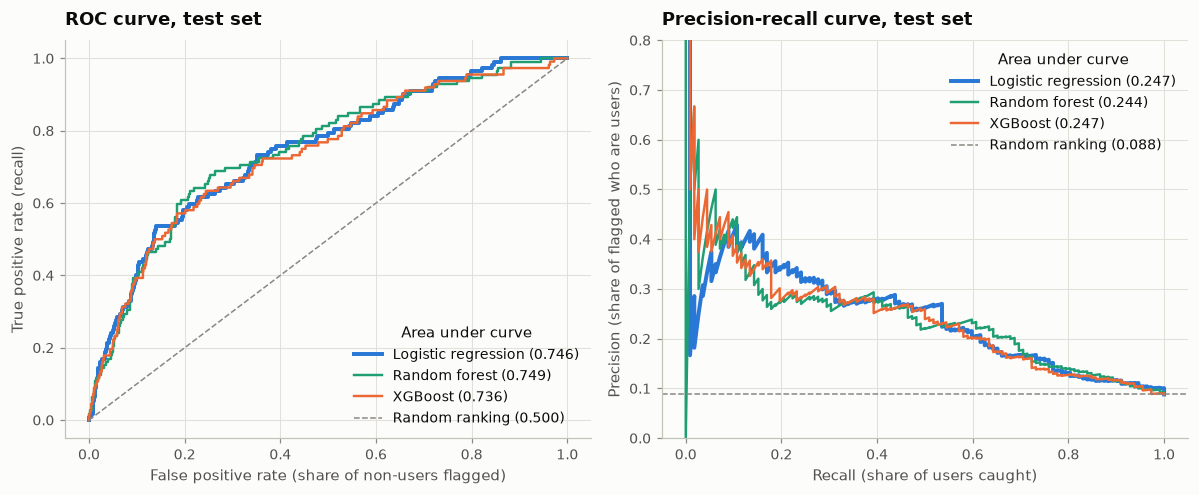

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for name, s in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    prec, rec, _ = precision_recall_curve(y_test, s)
    lw = 2.6 if name == CHOSEN else 1.6
    axes[0].plot(fpr, tpr, color=MODEL_COLOURS[name], linewidth=lw, label=f"{name} ({test_table.loc[name, 'ROC-AUC']:.3f})")
    axes[1].plot(rec, prec, color=MODEL_COLOURS[name], linewidth=lw, label=f"{name} ({test_table.loc[name, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Random ranking (0.500)")
axes[1].axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1, label=f"Random ranking ({y_test.mean():.3f})")
axes[0].set(xlabel="False positive rate (share of non-users flagged)", ylabel="True positive rate (recall)", title="ROC curve, test set")
axes[1].set(xlabel="Recall (share of users caught)", ylabel="Precision (share of flagged who are users)", title="Precision-recall curve, test set")
axes[1].set_ylim(0, 0.8)
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", title="Area under curve")
fig.tight_layout()
fig.savefig(FIG_DIR / "17_test_roc_pr_curves.png")
plt.show()

In [14]:
def lift_table(y, score):
    """Decile 1 = the 10% with the highest scores."""
    d = pd.DataFrame({"y": np.asarray(y), "score": np.asarray(score)}).sort_values("score", ascending=False).reset_index(drop=True)
    d["decile"] = np.arange(len(d)) * 10 // len(d) + 1
    t = d.groupby("decile").agg(people=("y", "size"), users=("y", "sum"), usage_rate=("y", "mean"))
    t["lift"] = t["usage_rate"] / d["y"].mean()
    t["cumulative share of users captured"] = t["users"].cumsum() / d["y"].sum()
    return t


lifts = {name: lift_table(y_test, s) for name, s in test_scores.items()}
print(f"Lift by decile on the test set, {CHOSEN}:")
display(fmt(lifts[CHOSEN], {"usage_rate": "{:.1%}", "lift": "{:.2f}x", "cumulative share of users captured": "{:.1%}"}))

capture = pd.DataFrame({name: t["cumulative share of users captured"].loc[[1, 2, 3, 5]].to_numpy() for name, t in lifts.items()},
                       index=["Top 10%", "Top 20%", "Top 30%", "Top 50%"]).T
capture["Top-decile lift"] = [lifts[n].loc[1, "lift"] for n in capture.index]
print("Share of all test-set users captured in the top X% of scores:")
display(fmt(capture, {c: "{:.1%}" for c in capture.columns[:-1]} | {"Top-decile lift": "{:.2f}x"}))

Lift by decile on the test set, Logistic regression:


,people,users,usage_rate,lift,cumulative share of users captured
decile,,,,,
1,128,35,27.3%,3.11x,31.2%
2,127,25,19.7%,2.24x,53.6%
3,128,11,8.6%,0.98x,63.4%
4,127,11,8.7%,0.99x,73.2%
5,127,4,3.1%,0.36x,76.8%
6,128,7,5.5%,0.62x,83.0%
7,127,9,7.1%,0.81x,91.1%
8,128,4,3.1%,0.36x,94.6%
9,127,6,4.7%,0.54x,100.0%


Share of all test-set users captured in the top X% of scores:


,Top 10%,Top 20%,Top 30%,Top 50%,Top-decile lift
Logistic regression,31.2%,53.6%,63.4%,76.8%,3.11x
Random forest,30.4%,50.0%,68.8%,79.5%,3.02x
XGBoost,32.1%,52.7%,63.4%,75.9%,3.20x


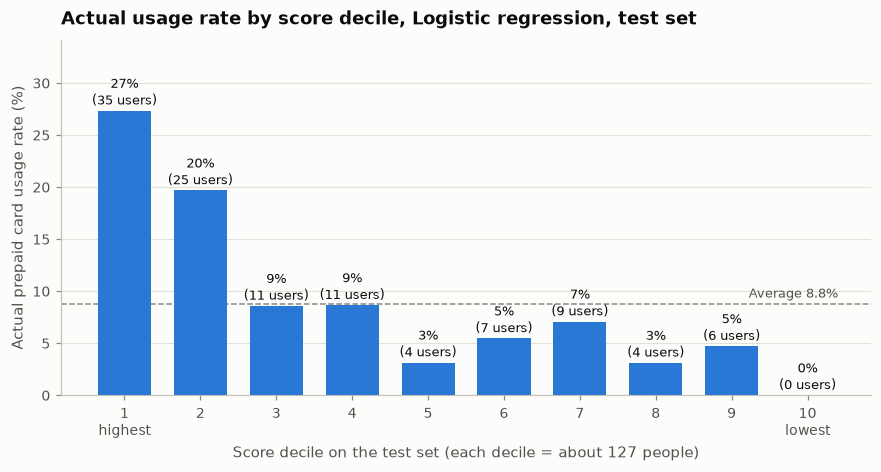

In [15]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
t = lifts[CHOSEN]
bars = ax.bar(t.index, t["usage_rate"] * 100, color=BLUE, width=0.7, zorder=3)
for x, (rate, users) in enumerate(zip(t["usage_rate"], t["users"]), start=1):
    ax.text(x, rate * 100 + 0.6, f"{rate:.0%}\n({users} users)", ha="center", fontsize=8.5, color=INK)
ax.axhline(y_test.mean() * 100, color=MUTED, linestyle="--", linewidth=1)
ax.text(10.4, y_test.mean() * 100 + 0.6, f"Average {y_test.mean():.1%}", ha="right", fontsize=8.5, color=INK2)
ax.set_xticks(t.index, [f"{d}\n{'highest' if d == 1 else 'lowest' if d == 10 else ''}" for d in t.index])
ax.set_xlabel("Score decile on the test set (each decile = about 127 people)")
ax.set_ylabel("Actual prepaid card usage rate (%)")
ax.set_ylim(0, t["usage_rate"].max() * 100 * 1.25)
ax.set_title(f"Actual usage rate by score decile, {CHOSEN}, test set")
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "18_test_lift_by_decile.png")
plt.show()

In [16]:
# How uncertain are the test-set numbers? Resample the 1,274 test respondents 2,000 times (bootstrap).
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
boot = {k: [] for k in ["chosen ROC-AUC", "chosen PR-AUC", "XGBoost minus chosen, PR-AUC", "Random forest minus chosen, PR-AUC"]}
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].sum() == 0:
        continue
    pr = {n: average_precision_score(yt[i], s[i]) for n, s in test_scores.items()}
    boot["chosen ROC-AUC"].append(roc_auc_score(yt[i], test_scores[CHOSEN][i]))
    boot["chosen PR-AUC"].append(pr[CHOSEN])
    boot["XGBoost minus chosen, PR-AUC"].append(pr["XGBoost"] - pr[CHOSEN])
    boot["Random forest minus chosen, PR-AUC"].append(pr["Random forest"] - pr[CHOSEN])
ci = pd.DataFrame({k: {"2.5%": np.percentile(v, 2.5), "median": np.median(v), "97.5%": np.percentile(v, 97.5)} for k, v in boot.items()}).T
print("95% bootstrap intervals on the test set:")
display(fmt(ci, "{:+.3f}"))

95% bootstrap intervals on the test set:


,2.5%,median,97.5%
chosen ROC-AUC,+0.699,+0.746,+0.794
chosen PR-AUC,+0.186,+0.253,+0.328
"XGBoost minus chosen, PR-AUC",-0.034,+0.000,+0.034
"Random forest minus chosen, PR-AUC",-0.048,-0.002,+0.042


**Takeaways**

- **The test results confirm cross-validation.** The chosen model scores **ROC-AUC 0.746 and PR-AUC 0.247** on the test set, against 0.730 and 0.225 in cross-validation. There is no sign of overfitting.
- **The ranking of the three models shuffles on the test set**: the random forest has the best ROC-AUC (0.749), XGBoost and logistic regression share the best PR-AUC (0.247), and logistic regression has the best recall at the top 20% (53.6%). This is what a tie looks like. The bootstrap intervals for the PR-AUC gaps (XGBoost minus logistic regression: −0.034 to +0.034; random forest minus logistic regression: −0.048 to +0.042) both include zero.
- **At the top-20% rule** (cut-off 0.602, fixed on training data), the model flags 246 of 1,274 people (19.3%) and catches **60 of the 112 users (recall 53.6%)**. Of those flagged, **24.4% are users (precision), 2.77 times the 8.8% average.** It misses 52 users and flags 186 non-users.
- **Accuracy would be misleading.** The model's accuracy is 81.3%, lower than the 91.2% scored by flagging no one, which is useless. This is why accuracy is not used to judge models here.
- **Lift is concentrated in the top two deciles.** The top 10% of scores has a usage rate of 27.3% (3.11x) and the next 10% has 19.7%; from the third decile down, every decile is at or below the 8.8% average, and the lowest decile has no users at all. **The top 10% of scores holds 31.2% of all users, the top 20% holds 53.6% and the top 30% holds 63.4%.**
- **The numbers are uncertain.** With only 112 users in the test set, the 95% bootstrap interval for the chosen model's ROC-AUC is 0.699–0.794, and for its PR-AUC 0.186–0.328. The 53.6% recall on the test set is higher than the 48.7% on training scores; the truth is probably in between, so plan on **about half of users in the top 20%**.

---
# 8. Honest reading: what the model can and cannot do

**What it can do**
- **Sort a population into a high-use and a low-use group.** People in the top 20% of scores use prepaid cards at about 2.4–2.8 times the average rate (2.43x on training scores, 2.77x on the test set), and that group contains roughly half of all users. People in the bottom half are much less likely to be users. For a marketing list or for sizing an at-risk group, this is useful.
- **Do so with a model that can be explained.** Every score is a weighted sum of 17 survey answers, so Tasks C and D can say which characteristics are associated with higher scores.
- **Hold up on new data.** Test-set performance matched cross-validation.

**What it cannot do**
- **It cannot identify individual users with confidence.** Even in the top 20%, three in four people flagged are not users, and almost half of all users fall outside the top 20%.
- **Its scores are rankings, not probabilities.** Because of the class weights, a score of 0.6 does not mean a 60% chance. To read scores as probabilities they would need to be recalibrated, which was not done. Tasks C and D should compare people by score rank or by actual usage rates within score groups, not by the score itself.
- **It cannot be made much better with these predictors.** Three very different algorithms, tuned, all land at a ROC-AUC near 0.73. The limit is the information in the 17 predictors, not the algorithm.
- **It shows associations, not causes.** A high weight on "contacted by a debt collector" means the two go together, not that one causes the other.
- **It describes this 2016 sample.** Survey weights were ignored (as the brief requires), so the usage rates are not national estimates.

---
# 9. Hand-off

### Files produced

| File | Contents |
|---|---|
| `data/test_scores.csv` | 1,274 test respondents: `PUF_ID`, `PRODUSE_3`, `score_logit`, `score_rf`, `score_xgb`, `score_chosen` |
| `data/train_oof_scores.csv` | 5,093 training respondents, same columns. Out-of-fold scores: each person scored by a model that did not see them |
| `models/chosen_model.joblib` | The chosen pipeline (preparation + model), fitted on the full training set |
| `figures/15–18` | Charts from this notebook |

In [17]:
def score_frame(index, y, scores):
    out = pd.DataFrame({"PRODUSE_3": np.asarray(y)}, index=index)
    for name, spec in MODELS.items():
        out[f"score_{spec['key']}"] = scores[name]
    out["score_chosen"] = scores[CHOSEN]
    out.index.name = "PUF_ID"
    return out


test_out = score_frame(X_test.index, y_test, test_scores)
oof_out = score_frame(X_train.index, y_train, oof)
test_out.to_csv(DATA_DIR / "test_scores.csv")
oof_out.to_csv(DATA_DIR / "train_oof_scores.csv")
joblib.dump(chosen_model, MODEL_DIR / "chosen_model.joblib")

reloaded = joblib.load(MODEL_DIR / "chosen_model.joblib")
handoff_checks = {
    "test_scores.csv has one row per test respondent": len(pd.read_csv(DATA_DIR / "test_scores.csv")) == len(X_test),
    "train_oof_scores.csv has one row per training respondent": len(pd.read_csv(DATA_DIR / "train_oof_scores.csv")) == len(X_train),
    "Columns are PUF_ID, PRODUSE_3, score_logit, score_rf, score_xgb, score_chosen":
        list(pd.read_csv(DATA_DIR / "test_scores.csv").columns) == ["PUF_ID", "PRODUSE_3", "score_logit", "score_rf", "score_xgb", "score_chosen"],
    "Saved model reproduces the test scores": bool(np.allclose(reloaded.predict_proba(X_test)[:, 1], test_out["score_chosen"])),
    "score_chosen equals the chosen model's column": bool(np.allclose(test_out["score_chosen"], test_out[f"score_{chosen_spec['key']}"])),
    "No missing scores": bool(test_out.notna().all().all() and oof_out.notna().all().all()),
}
display(pd.DataFrame({"Check": list(handoff_checks), "Result": ["PASS" if ok else "FAIL" for ok in handoff_checks.values()]}))
assert all(handoff_checks.values())
print("Saved: data/test_scores.csv, data/train_oof_scores.csv, models/chosen_model.joblib")

,Check,Result
0,test_scores.csv has one row per test respondent,PASS
1,train_oof_scores.csv has one row per training respondent,PASS
2,"Columns are PUF_ID, PRODUSE_3, score_logit, score_rf, score_xgb, score_chosen",PASS
3,Saved model reproduces the test scores,PASS
4,score_chosen equals the chosen model's column,PASS
5,No missing scores,PASS


Saved: data/test_scores.csv, data/train_oof_scores.csv, models/chosen_model.joblib


In [18]:
t = test_table.loc[CHOSEN]
chosen_record = pd.DataFrame({"Value": [
    CHOSEN, best_table.loc[CHOSEN, "Best settings"], "class_weight='balanced'",
    f"Flag the top {TOP_SHARE:.0%} of scores", f"{THRESHOLD:.3f} (score_chosen >= this value)",
    f"{cv_compare.loc[CHOSEN, 'ROC-AUC']:.3f} ± {cv_compare.loc[CHOSEN, 'ROC-AUC sd']:.3f}",
    f"{cv_compare.loc[CHOSEN, 'PR-AUC']:.3f} ± {cv_compare.loc[CHOSEN, 'PR-AUC sd']:.3f}",
    f"{t['ROC-AUC']:.3f}", f"{t['PR-AUC']:.3f}",
    f"recall {t['Recall']:.1%}, precision {t['Precision']:.1%}, lift {t['Lift']:.2f}x",
    "score_chosen in data/test_scores.csv and data/train_oof_scores.csv; models/chosen_model.joblib"]},
    index=["Chosen model", "Tuned settings", "Class imbalance handling", "Recommended rule", "Score cutoff",
           "Cross-validated ROC-AUC", "Cross-validated PR-AUC", "Test ROC-AUC", "Test PR-AUC", "Test, top-20% rule", "Where to find it"])
display(chosen_record)

,Value
Chosen model,Logistic regression
Tuned settings,C=0.3
Class imbalance handling,class_weight='balanced'
Recommended rule,Flag the top 20% of scores
Score cutoff,0.602 (score_chosen >= this value)
Cross-validated ROC-AUC,0.730 ± 0.030
Cross-validated PR-AUC,0.225 ± 0.028
Test ROC-AUC,0.746
Test PR-AUC,0.247
"Test, top-20% rule","recall 53.6%, precision 24.4%, lift 2.77x"


### How Tasks C and D use this

```python
import joblib, pandas as pd
import prep

scores_test = pd.read_csv("data/test_scores.csv", index_col="PUF_ID")       # final numbers
scores_oof = pd.read_csv("data/train_oof_scores.csv", index_col="PUF_ID")   # profiling 5,093 people without leakage
model = joblib.load("models/chosen_model.joblib")                           # preparation + logistic regression
coefs = pd.Series(model.named_steps["model"].coef_[0], index=prep.readable_names(model.named_steps["prep"]))
```

### Notes for the next tasks

- **Use `score_chosen`.** The other three score columns are there so the three models can be compared, not to be mixed.
- **Treat scores as rankings.** "Top 20%" means `score_chosen >= 0.602` (the cut-off fixed on training data), or the top 20% by rank within whichever group is being profiled. Report actual usage rates within score groups, not average scores.
- **Out-of-fold scores come from five slightly different models** (one per fold). They are fine for ranking and profiling within the training set; the test-set scores come from the single final model.
- **Task C:** the model is a logistic regression on standardised inputs, so `exp(weight)` gives the odds ratio for a one-standard-deviation change (or for a yes versus no). Treat savings, ability to raise \$2,000 and the well-being score as one liquidity group, as Task A advised; their weights split a shared signal between them.
- **Task D:** for screening at-risk groups, the top 30% (61.4% of users caught on training scores) may suit better than the top 20%; Section 6 has the full trade-off table.